# ⚡ PowerCast Part 2:
###  Exploratory Data Analysis (EDA) — Consumption Patterns

---

**Project goal:** Predict a home's hourly consumption for the **next 24 hours** from its past usage, and flag the **expected peak hour**.

**Goal of this notebook:**
Analyze household electricity consumption, discover **daily and weekly patterns** (and how stable the **daily peak hour** is), and visualize them to guide feature engineering and modeling.

⚠️ EDA uses the **train split only** so no information from validation/test leaks into our decisions.

## 1. Setup & Load Data

In [24]:
from google.colab import drive
drive.mount('/content/drive')

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

BASE = '/content/drive/MyDrive/PowerCast'
FIG = f'{BASE}/figures'
os.makedirs(FIG, exist_ok=True)

# ---- one consistent, readable style for all figures ----
C_MAIN, C_ACC, C_GREY = '#2B6CB0', '#E8590C', '#868E96'   # blue, orange, grey
sns.set_theme(style='whitegrid', context='notebook', font_scale=1.05)
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 200,
    'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.labelsize': 11, 'axes.spines.top': False, 'axes.spines.right': False,
    'grid.alpha': 0.35, 'legend.frameon': False,
})
HEAT = 'YlOrRd'

def save(name):
    plt.savefig(f'{FIG}/{name}.png', bbox_inches='tight', facecolor='white')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [25]:
df = pd.read_csv(f'{BASE}/data/hourly_clean.csv', index_col=0, parse_dates=True)
TARGET = 'Global_active_power'

# train only for pattern discovery
train = df[df['split'] == 'train'].copy()

# calendar features
train['hour'] = train.index.hour
train['dayofweek'] = train.index.dayofweek   # 0 = Monday
train['month'] = train.index.month
train['year'] = train.index.year
train['is_weekend'] = (train['dayofweek'] >= 5).astype(int)
DAYS = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
MONTHS = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

print('All data:', df.shape, '| Train:', train.shape)
print('Train period:', train.index.min(), '->', train.index.max())
train[TARGET].describe().round(3)

All data: (34589, 9) | Train: (26671, 14)
Train period: 2006-12-16 17:00:00 -> 2009-12-31 23:00:00


,Global_active_power
count,26671.000
mean,1.100
std,0.928
min,0.124
25%,0.330
50%,0.793
75%,1.596
max,6.561


## 2. Overview of Consumption

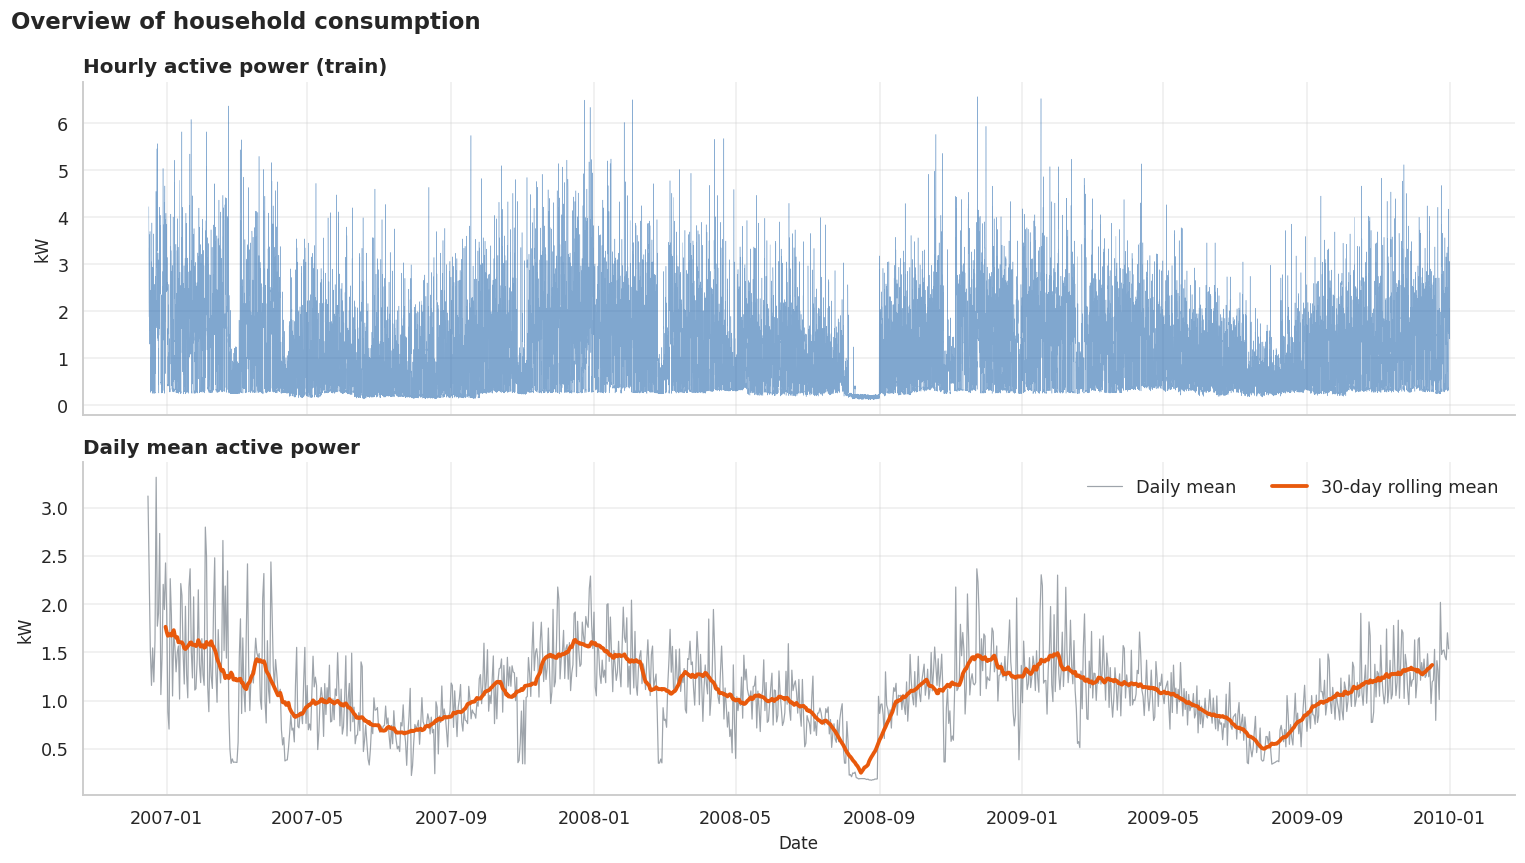

In [26]:
daily = train[TARGET].resample('D').mean()

fig, ax = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
ax[0].plot(train.index, train[TARGET], lw=0.3, color=C_MAIN, alpha=0.6)
ax[0].set(title='Hourly active power (train)', ylabel='kW')

ax[1].plot(daily, lw=0.8, color=C_GREY, alpha=0.8, label='Daily mean')
ax[1].plot(daily.rolling(30, center=True).mean(), color=C_ACC, lw=2.5, label='30-day rolling mean')
ax[1].set(title='Daily mean active power', ylabel='kW', xlabel='Date')
ax[1].legend(loc='upper right', ncol=2)
fig.suptitle('Overview of household consumption', fontsize=15, fontweight='bold', x=0.01, ha='left')
plt.tight_layout()
save('01_overview_timeseries')
plt.show()

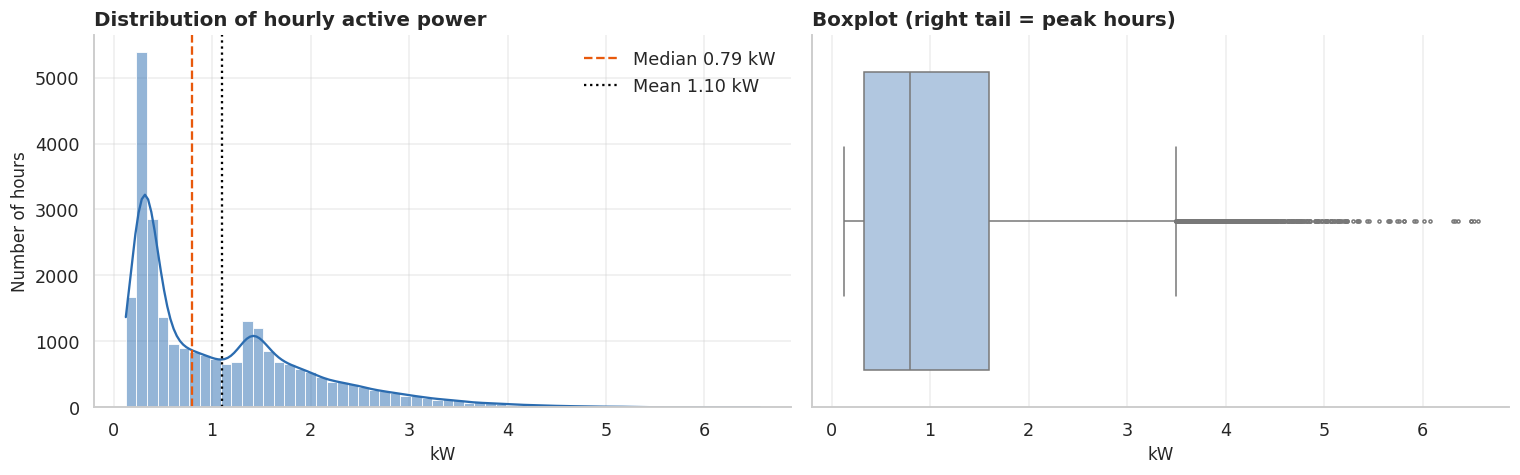

Skewness: 1.31


In [27]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(train[TARGET], bins=60, kde=True, color=C_MAIN, ax=ax[0])
med = train[TARGET].median(); mean = train[TARGET].mean()
ax[0].axvline(med, color=C_ACC, ls='--', lw=1.5, label=f'Median {med:.2f} kW')
ax[0].axvline(mean, color='black', ls=':', lw=1.5, label=f'Mean {mean:.2f} kW')
ax[0].set(title='Distribution of hourly active power', xlabel='kW', ylabel='Number of hours')
ax[0].legend()

sns.boxplot(x=train[TARGET], color='#A9C7E8', fliersize=2, ax=ax[1])
ax[1].set(title='Boxplot (right tail = peak hours)', xlabel='kW')
plt.tight_layout()
save('02_distribution')
plt.show()

print('Skewness:', round(train[TARGET].skew(), 2))

## 3. Long-term Trend & Yearly Seasonality
Only full calendar months (2007-01 to 2009-12) are used, because Dec 2006 is a partial month.

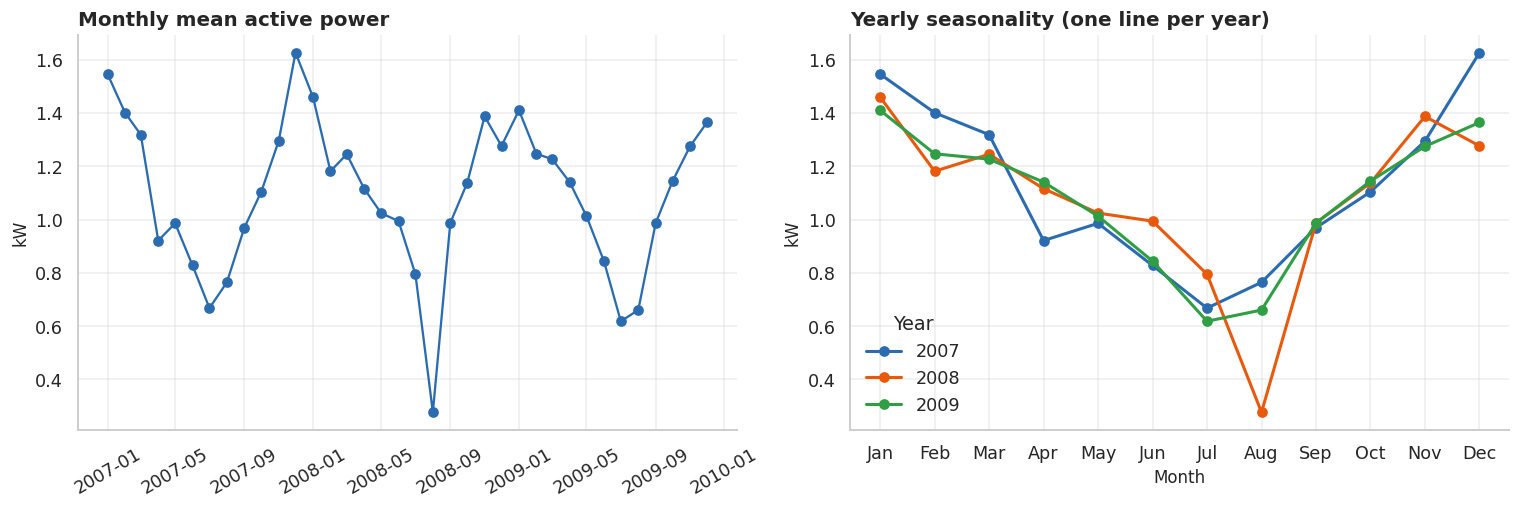

In [28]:
m = train.loc['2007-01':'2009-12', TARGET].resample('MS').mean()
mp = m.groupby([m.index.year, m.index.month]).mean().unstack(0)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ax[0].plot(m.index, m.values, marker='o', color=C_MAIN)
ax[0].set(title='Monthly mean active power', ylabel='kW')
ax[0].tick_params(axis='x', rotation=30)

for col, c in zip(mp.columns, ['#2B6CB0', '#E8590C', '#2F9E44']):
    ax[1].plot(mp.index, mp[col], marker='o', lw=2, color=c, label=str(col))
ax[1].set_xticks(range(1, 13))
ax[1].set_xticklabels(MONTHS)
ax[1].set(title='Yearly seasonality (one line per year)', xlabel='Month', ylabel='kW')
ax[1].legend(title='Year')
plt.tight_layout()
save('03_monthly_seasonality')
plt.show()

## 4. Daily Pattern (hour of day)

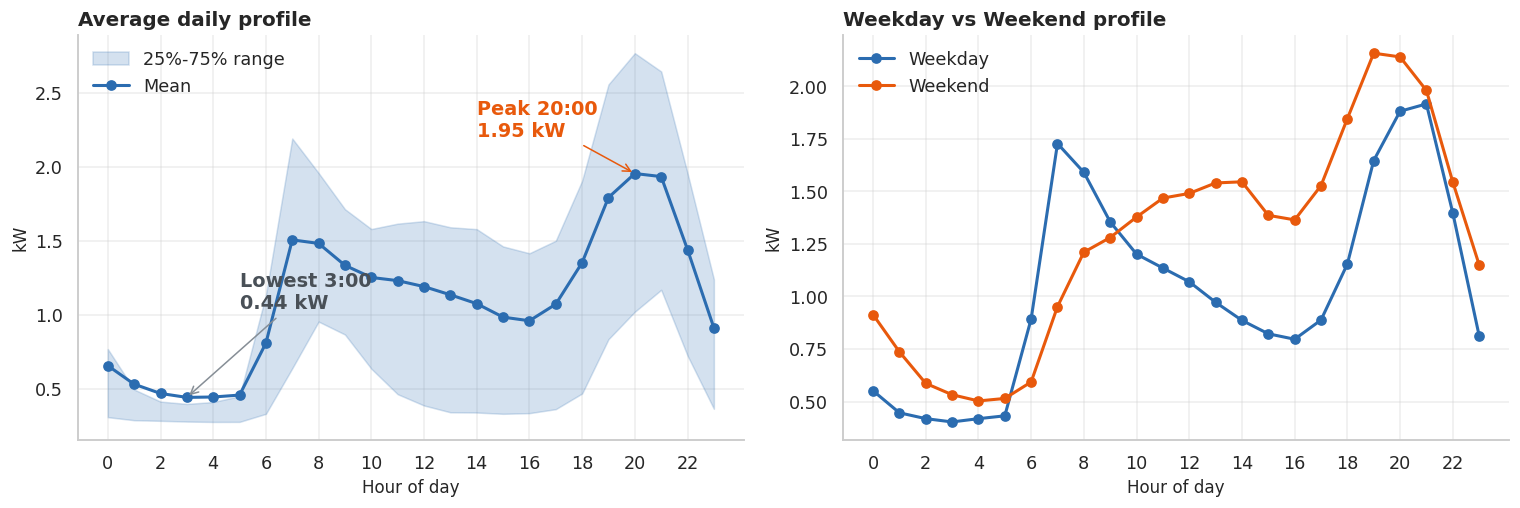

Peak hour: 20:00 (1.95 kW)
Lowest hour: 3:00 (0.44 kW)


In [29]:
g = train.groupby('hour')[TARGET]
hourly = pd.DataFrame({'mean': g.mean(), 'q25': g.quantile(0.25), 'q75': g.quantile(0.75)})

wk = train.groupby(['is_weekend', 'hour'])[TARGET].mean().unstack(0)
wk.columns = ['Weekday', 'Weekend']
hm = hourly['mean']

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ax[0].fill_between(hourly.index, hourly['q25'], hourly['q75'], color=C_MAIN, alpha=0.2, label='25%-75% range')
ax[0].plot(hourly.index, hourly['mean'], marker='o', color=C_MAIN, lw=2, label='Mean')
ax[0].annotate(f'Peak {hm.idxmax()}:00\n{hm.max():.2f} kW', xy=(hm.idxmax(), hm.max()),
               xytext=(hm.idxmax() - 6, hm.max() + 0.25), arrowprops=dict(arrowstyle='->', color=C_ACC),
               color=C_ACC, fontweight='bold')
ax[0].annotate(f'Lowest {hm.idxmin()}:00\n{hm.min():.2f} kW', xy=(hm.idxmin(), hm.min()),
               xytext=(hm.idxmin() + 2, hm.min() + 0.6), arrowprops=dict(arrowstyle='->', color=C_GREY),
               color='#495057', fontweight='bold')
ax[0].set_xticks(range(0, 24, 2))
ax[0].set(title='Average daily profile', xlabel='Hour of day', ylabel='kW')
ax[0].legend(loc='upper left')

ax[1].plot(wk.index, wk['Weekday'], marker='o', lw=2, color=C_MAIN, label='Weekday')
ax[1].plot(wk.index, wk['Weekend'], marker='o', lw=2, color=C_ACC, label='Weekend')
ax[1].set_xticks(range(0, 24, 2))
ax[1].set(title='Weekday vs Weekend profile', xlabel='Hour of day', ylabel='kW')
ax[1].legend()
plt.tight_layout()
save('04_daily_profile')
plt.show()

print(f'Peak hour: {hm.idxmax()}:00 ({hm.max():.2f} kW)')
print(f'Lowest hour: {hm.idxmin()}:00 ({hm.min():.2f} kW)')

## 5. Weekly Pattern (day of week)

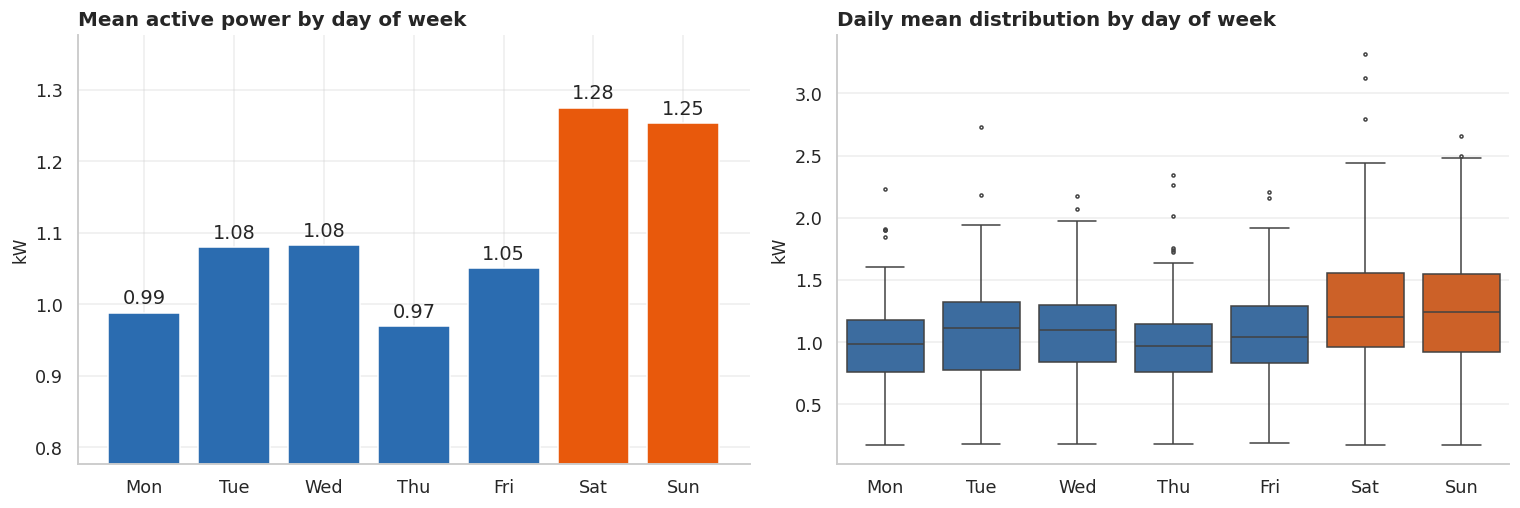

In [30]:
dow = train.groupby('dayofweek')[TARGET].mean()

daily_df = train[TARGET].resample('D').mean().to_frame('kW')
daily_df['dow'] = daily_df.index.dayofweek

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
colors = [C_MAIN] * 5 + [C_ACC] * 2
bars = ax[0].bar(DAYS, dow.values, color=colors)
ax[0].bar_label(bars, fmt='%.2f', padding=3)
ax[0].set(title='Mean active power by day of week', ylabel='kW')
ax[0].set_ylim(dow.min() * 0.8, dow.max() * 1.08)

sns.boxplot(data=daily_df, x='dow', y='kW', hue='dow', palette=colors, legend=False, fliersize=2, ax=ax[1])
ax[1].set_xticks(range(7))
ax[1].set_xticklabels(DAYS)
ax[1].set(title='Daily mean distribution by day of week', xlabel='', ylabel='kW')
plt.tight_layout()
save('05_weekly_profile')
plt.show()

## 6. Hour x Day Heatmap

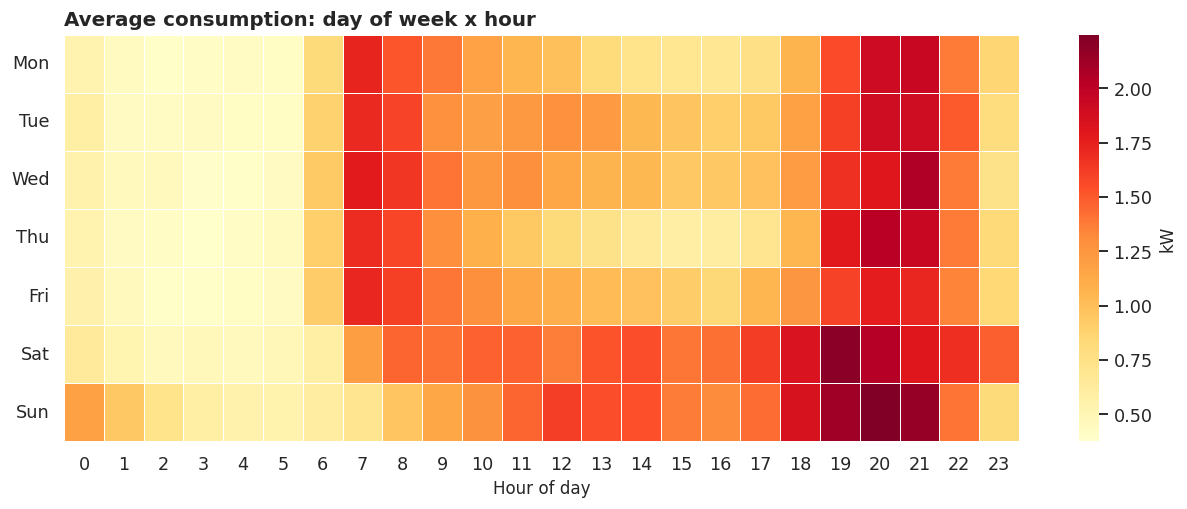

In [31]:
pv = train.pivot_table(index='dayofweek', columns='hour', values=TARGET, aggfunc='mean')
pv.index = DAYS

plt.figure(figsize=(14, 4.8))
sns.heatmap(pv, cmap=HEAT, cbar_kws={'label': 'kW'}, linewidths=0.4, linecolor='white')
plt.title('Average consumption: day of week x hour')
plt.xlabel('Hour of day')
plt.ylabel('')
plt.yticks(rotation=0)
save('06_heatmap_day_hour')
plt.show()

## 7. Seasonal Daily Pattern (month x hour)

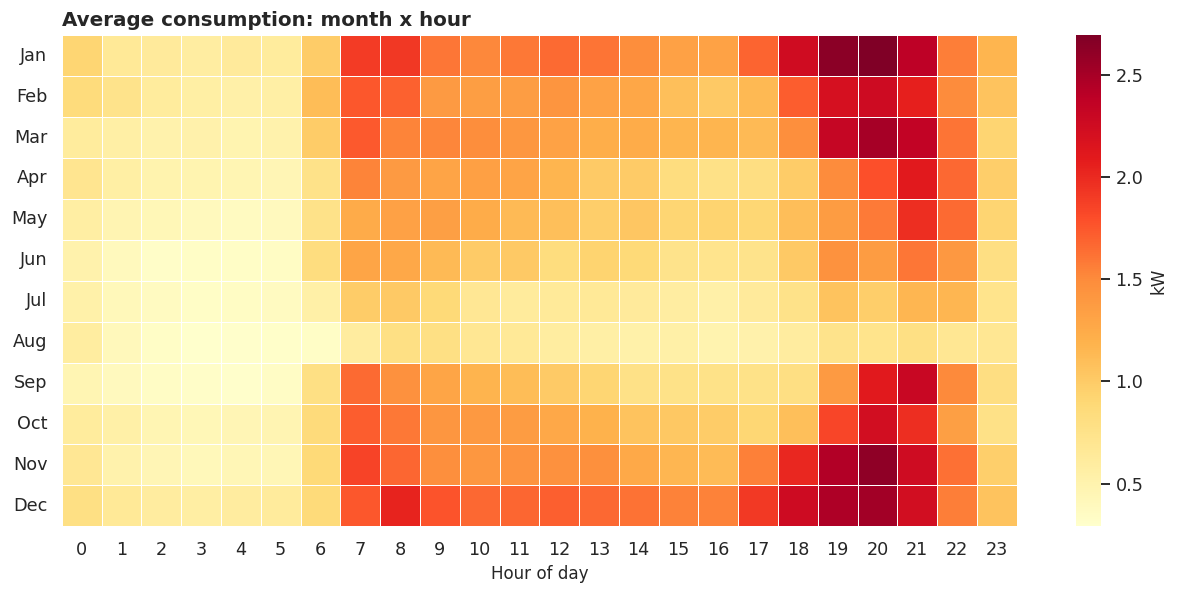

In [32]:
pm = train.pivot_table(index='month', columns='hour', values=TARGET, aggfunc='mean')
pm.index = MONTHS

plt.figure(figsize=(14, 5.8))
sns.heatmap(pm, cmap=HEAT, cbar_kws={'label': 'kW'}, linewidths=0.4, linecolor='white')
plt.title('Average consumption: month x hour')
plt.xlabel('Hour of day')
plt.ylabel('')
plt.yticks(rotation=0)
save('07_heatmap_month_hour')
plt.show()

## 8. Daily Peak Hour (the hour we must flag)
The project must flag the expected peak hour of each day. Here we check, for every day, which hour was actually the highest, and how stable that hour is.

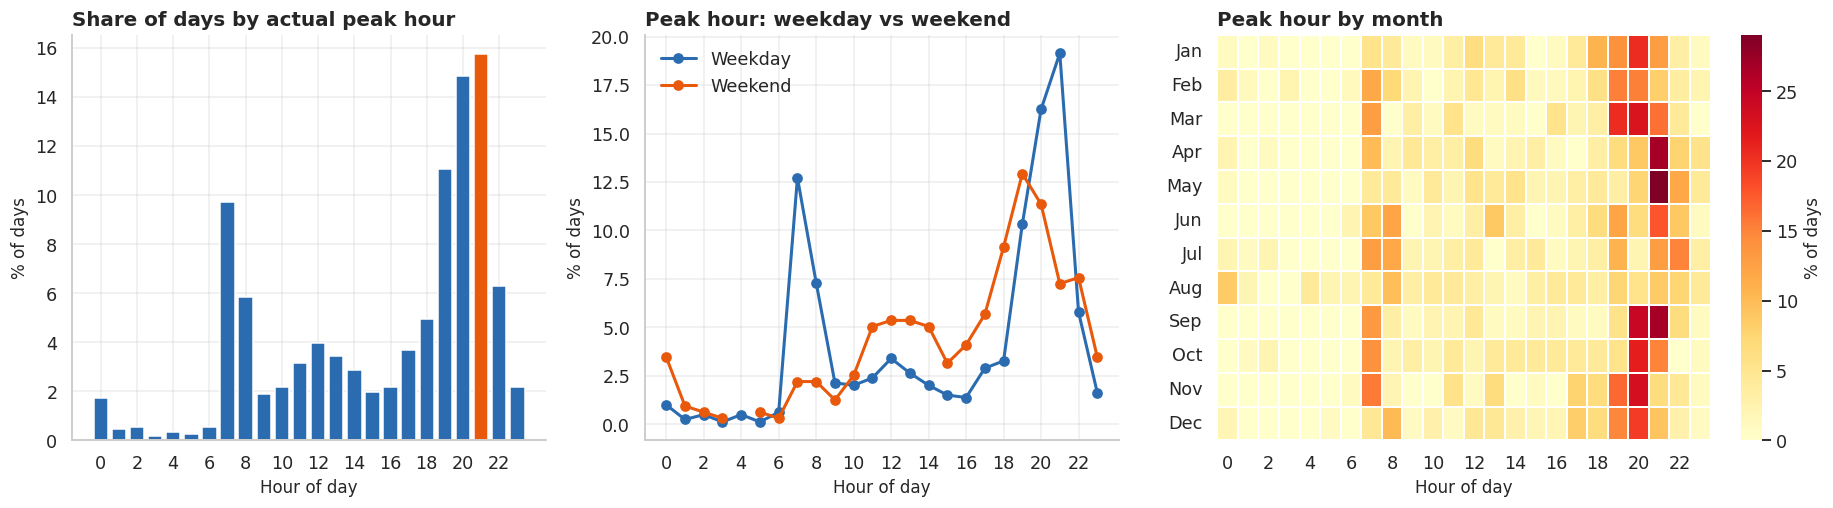

Complete days analysed: 1111
Most common peak hour: 21:00 (15.8% of days)
Days whose peak is between 19:00 and 22:00: 48.0%
Days whose peak is within +-1h of 21:00: 36.9%
Std of daily peak hour: 5.8 h


In [33]:
# only complete days (24 hourly values) so the daily peak is not biased
cnt = train[TARGET].resample('D').count()
full_days = cnt[cnt == 24].index
tmp = train[TARGET].copy()
day_key = tmp.index.normalize()
tmp = tmp[day_key.isin(full_days)]
dkey = tmp.index.normalize()

peak_hour = tmp.groupby(dkey).apply(lambda s: s.idxmax().hour)
peak_df = peak_hour.to_frame('peak_hour')
peak_df['dayofweek'] = peak_df.index.dayofweek
peak_df['is_weekend'] = (peak_df['dayofweek'] >= 5).astype(int)
peak_df['month'] = peak_df.index.month

cnts = peak_df['peak_hour'].value_counts().reindex(range(24), fill_value=0)
top = cnts.idxmax()

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={'width_ratios': [1, 1, 1.3]})
bar_colors = [C_ACC if h == top else C_MAIN for h in cnts.index]
ax[0].bar(cnts.index, cnts.values / cnts.sum() * 100, color=bar_colors)
ax[0].set_xticks(range(0, 24, 2))
ax[0].set(title='Share of days by actual peak hour', xlabel='Hour of day', ylabel='% of days')

ph = peak_df.groupby(['is_weekend', 'peak_hour']).size().unstack(0).reindex(range(24), fill_value=0)
ph = ph / ph.sum() * 100
ph.columns = ['Weekday', 'Weekend']
ax[1].plot(ph.index, ph['Weekday'], marker='o', lw=2, color=C_MAIN, label='Weekday')
ax[1].plot(ph.index, ph['Weekend'], marker='o', lw=2, color=C_ACC, label='Weekend')
ax[1].set_xticks(range(0, 24, 2))
ax[1].set(title='Peak hour: weekday vs weekend', xlabel='Hour of day', ylabel='% of days')
ax[1].legend()

pmh = peak_df.pivot_table(index='month', columns='peak_hour', values='dayofweek', aggfunc='count').fillna(0)
pmh = pmh.reindex(columns=range(24), fill_value=0)
pmh = pmh.div(pmh.sum(axis=1), axis=0) * 100
pmh.index = [MONTHS[k - 1] for k in pmh.index]
sns.heatmap(pmh, cmap=HEAT, ax=ax[2], cbar_kws={'label': '% of days'}, linewidths=0.3, linecolor='white')
ax[2].set(title='Peak hour by month', xlabel='Hour of day', ylabel='')
ax[2].tick_params(axis='y', rotation=0)
plt.tight_layout()
save('08_peak_hour_distribution')
plt.show()

in_eve = peak_df['peak_hour'].between(19, 22).mean() * 100
within1 = peak_df['peak_hour'].between(top - 1, top + 1).mean() * 100
print(f'Complete days analysed: {len(peak_df)}')
print(f'Most common peak hour: {top}:00 ({cnts.max() / cnts.sum() * 100:.1f}% of days)')
print(f'Days whose peak is between 19:00 and 22:00: {in_eve:.1f}%')
print(f'Days whose peak is within +-1h of {top}:00: {within1:.1f}%')
print(f'Std of daily peak hour: {peak_df["peak_hour"].std():.1f} h')

In [34]:
# How hard is it to guess the peak hour? Simple baselines on train (no model yet).
# 1) always predict the most common peak hour
# 2) predict yesterday's peak hour
b_fixed = (peak_df['peak_hour'] == top).mean() * 100
b_yday = (peak_df['peak_hour'] == peak_df['peak_hour'].shift(1)).mean() * 100
b_yday_pm1 = ((peak_df['peak_hour'] - peak_df['peak_hour'].shift(1)).abs() <= 1).mean() * 100
b_fixed_pm1 = ((peak_df['peak_hour'] - top).abs() <= 1).mean() * 100
print(f'Fixed hour ({top}:00): exact {b_fixed:.1f}% | within 1h {b_fixed_pm1:.1f}%')
print(f"Yesterday's peak hour : exact {b_yday:.1f}% | within 1h {b_yday_pm1:.1f}%")

Fixed hour (21:00): exact 15.8% | within 1h 36.9%
Yesterday's peak hour : exact 10.2% | within 1h 25.3%


## 9. Consumption by Appliance Group (sub-metering)

Sub-meters are in **Wh per minute**. Active power in kW x 1000 / 60 converts to the same unit, so the part not covered by the three sub-meters is `other`.
- `Sub_metering_1`: kitchen (dishwasher, oven, microwave)
- `Sub_metering_2`: laundry room (washing machine, dryer, fridge, light)
- `Sub_metering_3`: electric water heater and air conditioner

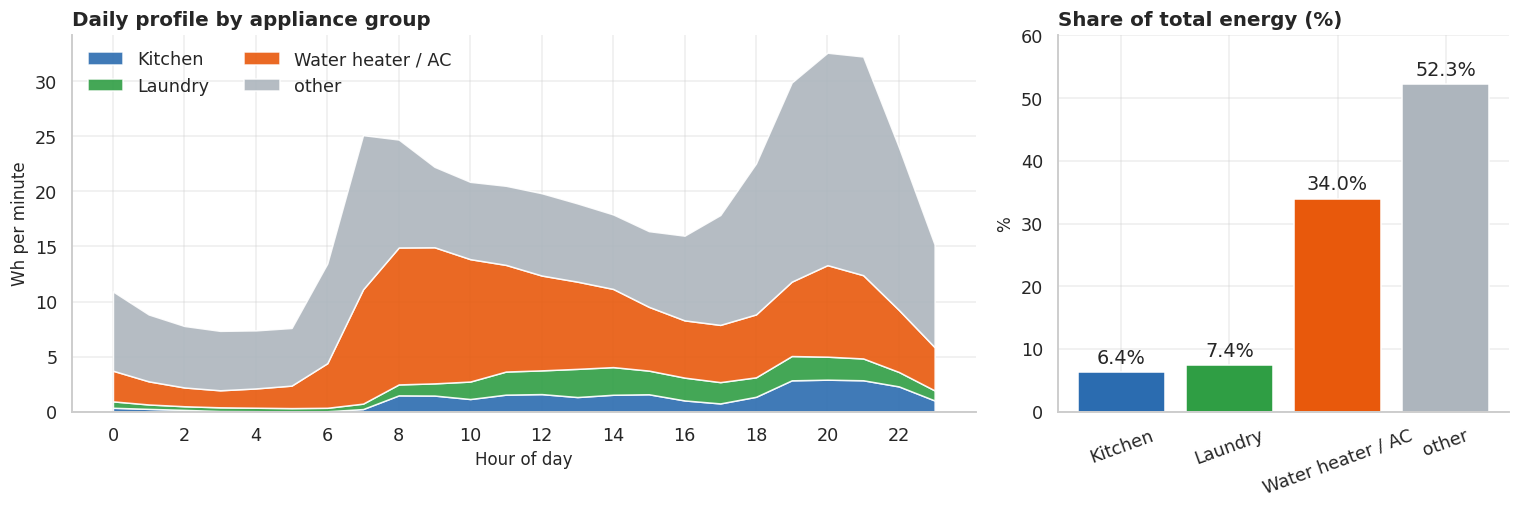

Kitchen               6.4
Laundry               7.4
Water heater / AC    34.0
other                52.3
dtype: float64


In [35]:
sub = ['Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']
names = {'Sub_metering_1': 'Kitchen', 'Sub_metering_2': 'Laundry', 'Sub_metering_3': 'Water heater / AC'}
GROUP_COLORS = ['#2B6CB0', '#2F9E44', '#E8590C', '#ADB5BD']

parts = train[sub].copy()
parts['other'] = (train[TARGET] * 1000 / 60 - train[sub].sum(axis=1)).clip(lower=0)
parts = parts.rename(columns=names)

by_hour = parts.groupby(train['hour']).mean()
share = parts.sum() / parts.sum().sum() * 100

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={'width_ratios': [2, 1]})
ax[0].stackplot(by_hour.index, by_hour.T.values, labels=by_hour.columns, colors=GROUP_COLORS, alpha=0.9)
ax[0].set_xticks(range(0, 24, 2))
ax[0].set(title='Daily profile by appliance group', xlabel='Hour of day', ylabel='Wh per minute')
ax[0].legend(loc='upper left', ncol=2)

bars = ax[1].bar(share.index, share.values, color=GROUP_COLORS)
ax[1].bar_label(bars, fmt='%.1f%%', padding=3)
ax[1].set(title='Share of total energy (%)', ylabel='%')
ax[1].set_ylim(0, share.max() * 1.15)
ax[1].tick_params(axis='x', rotation=20)
plt.tight_layout()
save('09_submetering')
plt.show()

print(share.round(1))

## 10. Autocorrelation (24h / 168h)
Autocorrelation shows how strongly consumption now resembles consumption N hours ago. Peaks at 24 and 168 confirm daily and weekly repetition.

Note: when forecasting the next 24 hours in one go, `lag_1` is only known for the first forecast hour. Lags of 24h and 168h are available for the whole horizon, so they are the key lag features.

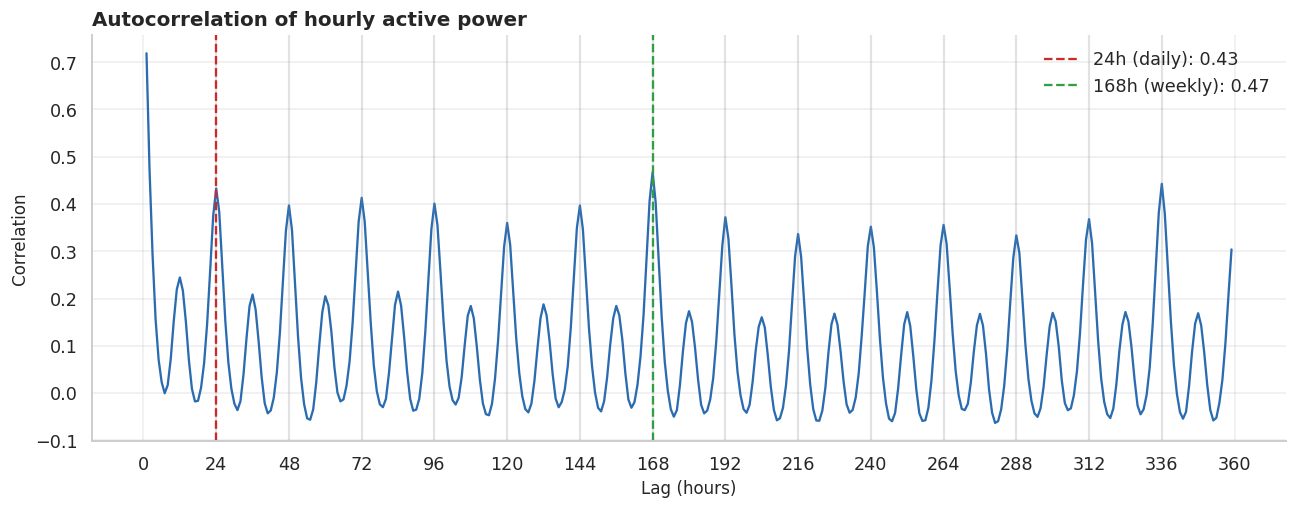

lag 1: 0.72 | lag 24: 0.43 | lag 48: 0.40 | lag 168: 0.47


In [36]:
lags = list(range(1, 24 * 15))
acf = [train[TARGET].autocorr(l) for l in lags]
ac = dict(zip(lags, acf))

plt.figure(figsize=(14, 4.8))
plt.plot(lags, acf, lw=1.5, color=C_MAIN)
for k in range(24, 24 * 15, 24):
    plt.axvline(k, color=C_GREY, alpha=0.15)
plt.axvline(24, color='#C92A2A', ls='--', label=f'24h (daily): {ac[24]:.2f}')
plt.axvline(168, color='#2F9E44', ls='--', label=f'168h (weekly): {ac[168]:.2f}')
plt.title('Autocorrelation of hourly active power')
plt.xlabel('Lag (hours)')
plt.ylabel('Correlation')
plt.xticks(range(0, 24 * 15 + 1, 24))
plt.legend()
save('10_autocorrelation')
plt.show()

print(f'lag 1: {ac[1]:.2f} | lag 24: {ac[24]:.2f} | lag 48: {ac[48]:.2f} | lag 168: {ac[168]:.2f}')

## 11. Key Findings & Modeling Implications


In [37]:
hm = hourly['mean']
wd = train[train['is_weekend'] == 0][TARGET].mean()
we = train[train['is_weekend'] == 1][TARGET].mean()
busiest = DAYS[int(dow.idxmax())]
quietest = DAYS[int(dow.idxmin())]
mon_mean = train.loc['2007-01':'2009-12'].groupby('month')[TARGET].mean()

print(f'Overall mean: {train[TARGET].mean():.2f} kW')
print(f'Daily peak (average profile) at {hm.idxmax()}:00 ({hm.max():.2f} kW), lowest at {hm.idxmin()}:00 ({hm.min():.2f} kW)')
print(f'Weekday mean {wd:.2f} kW vs weekend mean {we:.2f} kW ({(we / wd - 1) * 100:+.1f}%)')
print(f'Busiest day: {busiest} | quietest day: {quietest}')
print(f'Highest month: {MONTHS[int(mon_mean.idxmax()) - 1]} ({mon_mean.max():.2f} kW) | lowest month: {MONTHS[int(mon_mean.idxmin()) - 1]} ({mon_mean.min():.2f} kW)')
print(f'Autocorrelation: lag 24 = {ac[24]:.2f}, lag 168 = {ac[168]:.2f}')
print(f'Actual daily peak: most common {top}:00 ({cnts.max() / cnts.sum() * 100:.1f}% of days), 19-22h in {in_eve:.1f}% of days')

# August check: is August low in every full year?
aug = train.loc['2007-01':'2009-12', TARGET].resample('MS').mean()
for y in (2007, 2008, 2009):
    yr = aug[aug.index.year == y]
    others = yr[yr.index.month != 8].mean()
    print(f'{y}: Aug {yr[yr.index.month == 8].iloc[0]:.2f} kW vs mean of other months {others:.2f} kW')

# missing-value flag (only if it exists in the cleaned file)
if 'was_missing' in df.columns:
    print('Share of filled (was_missing) hours in train:', f"{train['was_missing'].mean() * 100:.2f}%")
else:
    print("'was_missing' column not found in hourly_clean.csv")

Overall mean: 1.10 kW
Daily peak (average profile) at 20:00 (1.95 kW), lowest at 3:00 (0.44 kW)
Weekday mean 1.03 kW vs weekend mean 1.26 kW (+22.3%)
Busiest day: Sat | quietest day: Thu
Highest month: Jan (1.47 kW) | lowest month: Aug (0.57 kW)
Autocorrelation: lag 24 = 0.43, lag 168 = 0.47
Actual daily peak: most common 21:00 (15.8% of days), 19-22h in 48.0% of days
2007: Aug 0.76 kW vs mean of other months 1.15 kW
2008: Aug 0.28 kW vs mean of other months 1.15 kW
2009: Aug 0.66 kW vs mean of other months 1.12 kW
Share of filled (was_missing) hours in train: 0.49%


### Key findings (from the outputs above)

- **Daily pattern:** consumption is lowest at night (**03:00, 0.44 kW**), rises in the morning, and reaches its highest average at **20:00 (1.95 kW)**.
- **Daily peak hour:** the actual peak hour of each day (section 8) is concentrated in the evening; see the printed share of days with peak between 19:00 and 22:00 and the baseline accuracies. Use them as the benchmark that the model's peak-hour flag must beat.
- **Weekly pattern:** weekends are higher than weekdays (**1.26 vs 1.03 kW, +22.3%**). Saturday is the busiest day and Thursday the quietest.
- **Yearly seasonality:** winter is higher than summer (**January 1.47 kW** highest, **August 0.57 kW** lowest). The August check printed above shows whether the dip repeats each year; a very low August is probably a change in household behaviour (e.g. absence), not only weather, so the month alone may not explain it.
- **Appliances:** water heater / AC are 34.0% of energy and kitchen + laundry 13.8%; **52.3% is "other"** (not covered by the three sub-meters, e.g. lighting and other devices). Check the stacked profile in section 9 to see which group rises in the evening.
- **Autocorrelation:** lag 1 = 0.72, lag 24 = 0.43, lag 48 = 0.40, lag 168 = 0.47. Moderate values at 24 and 168 confirm daily and weekly repetition, but it is not strong, so lags alone will not be enough.

### Implications for modeling

1. **Calendar features:** `hour`, `dayofweek`, `is_weekend`, `month` (cyclical sin/cos encoding for hour and month).
2. **Lag features:** `lag_24` and `lag_168` (available for the whole 24h horizon), rolling means over past data only. `lag_1` only helps the first forecast hours, so use it for short-term models or recursive forecasting.
3. **Baselines to beat:** *seasonal naive* with the value from 24h ago and from 168h ago; for the peak hour, the "fixed most-common hour" and "yesterday's peak hour" baselines from section 8.
4. **Peak flag:** derive the expected peak hour as the argmax of the 24 predicted hours, and evaluate it exactly and within ±1 hour.
5. **Metrics:** the distribution is right-skewed (skewness 1.31) with high evening peaks, so report MAE together with RMSE.
6. **Missing data:** keep the `was_missing` flag as a feature or use it to check whether filled hours hurt the error.